# Lab 5 - Multimodal Storytelling Pipeline
**COM SCI-X 455 - Week 5 - Megan Armani, PhD**

> Push to `genai-course/week5/`  |  GPU: T4 required

**Story theme:** *Pip the little robot helps a new family find a friendly daycare in their new neighborhood*
(linked to my capstone). Key from Colab Secrets: `UCLA_OPENAI_API_KEY` (or `OPENAI_API_KEY`).

---

## Setup - Run this first, models take ~10 min to download

In [1]:
!pip install -q -U diffusers openai
!pip install -q suno-bark streamlit playwright tabulate
!playwright install --with-deps chromium > /dev/null 2>&1
import os, torch
os.environ["SUNO_OFFLOAD_CPU"] = "True"     # keep Bark's three models off the GPU when idle, so SDXL fits later
# Bark checkpoints contain numpy objects; torch>=2.6 defaults to weights_only=True, which refuses to load them.
_orig_load = torch.load
torch.load = lambda *a, **k: _orig_load(*a, **{**k, "weights_only": False})
from bark import SAMPLE_RATE, generate_audio, preload_models
preload_models()   # ~5GB download
print("Bark ready")

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Bark ready


In [2]:
import os
def get_secret(*names):
    """Read a key from Colab Secrets (or env vars). Keys are never printed."""
    try:
        from google.colab import userdata
        for n in names:
            try:
                v = userdata.get(n)
                if v:
                    return v
            except Exception:
                pass
    except ImportError:
        pass
    for n in names:
        if os.environ.get(n):
            return os.environ[n]
    return None

OPENAI_KEY = get_secret("UCLA_OPENAI_API_KEY", "OPENAI_API_KEY")
ANTHROPIC_KEY = get_secret("ANTHROPIC_API_KEY", "UCLA_ANTHROPIC_API_KEY", "CLAUDE_API_KEY")
if OPENAI_KEY:
    os.environ["OPENAI_API_KEY"] = OPENAI_KEY
if ANTHROPIC_KEY:
    os.environ["ANTHROPIC_API_KEY"] = ANTHROPIC_KEY
print("OpenAI key found:", bool(OPENAI_KEY), "| Anthropic key found:", bool(ANTHROPIC_KEY))

import numpy as np, time, json, gc
from diffusers import StableDiffusionXLPipeline, AutoencoderKL
from scipy.io.wavfile import write as wav_write
from openai import OpenAI
from PIL import Image
import matplotlib.pyplot as plt, pandas as pd

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
client = OpenAI()

OpenAI key found: True | Anthropic key found: False


## Part 1 - Bark TTS: Voice Generation for 3 Scenes

In [3]:
SCENES = [
    {"id": 1, "script": "Once upon a time, [sighs] a family moved to a new city, and nobody knew where the baby could go during the day.", "voice": "v2/en_speaker_6"},
    {"id": 2, "script": "Then Pip the little robot rolled up to the door [gasps] and said: I know a cozy daycare just around the corner!", "voice": "v2/en_speaker_9"},
    {"id": 3, "script": "The next morning the baby waved goodbye [laughs] and the family smiled, because the new city finally felt like home. [music note]", "voice": "v2/en_speaker_3"},
]
CUES = ["sighs", "gasps", "laughs", "music note"]

In [4]:
audio_rows = []
for s in SCENES:
    t0 = time.time()
    audio = generate_audio(s["script"], history_prompt=s["voice"])
    gen_s = time.time() - t0
    duration = len(audio) / SAMPLE_RATE
    wav_write(f"scene{s['id']}_audio.wav", SAMPLE_RATE, (audio * 32767).astype(np.int16))
    print(f"Scene {s['id']}: {duration:.1f}s audio generated in {gen_s:.0f}s")
    audio_rows.append({"Scene": s["id"], "Audio (s)": round(duration, 1), "Generation (s)": round(gen_s, 1),
                       "Real-time factor": round(gen_s / duration, 1)})

# Which non-speech cues worked? Transcribe each clip; a cue word that shows up in the transcript was spoken literally.
for row, s in zip(audio_rows, SCENES):
    with open(f"scene{s['id']}_audio.wav", "rb") as f:
        text = client.audio.transcriptions.create(model="whisper-1", file=f).text
    cues = [c for c in CUES if f"[{c}]" in s["script"]]
    literal = [c for c in cues if c.split()[0].rstrip("s") in text.lower()]
    row.update({"Transcript": text, "Cues in script": ", ".join(cues),
                "Spoken literally": ", ".join(literal) or "none"})
audio_df = pd.DataFrame(audio_rows)
audio_df.to_csv("bark_audio_report.csv", index=False)
print(audio_df.to_markdown(index=False))
from IPython.display import Audio, display
for s in SCENES:
    display(Audio(f"scene{s['id']}_audio.wav"))

/usr/local/lib/python3.13/dist-packages/bark/generation.py:175: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with InferenceContext(), torch.inference_mode(), torch.no_grad(), autocast():
100%|██████████| 34/34 [00:54<00:00,  1.62s/it]


Scene 1: 13.4s audio generated in 94s


100%|██████████| 35/35 [00:55<00:00,  1.60s/it]


Scene 2: 14.0s audio generated in 84s


100%|██████████| 37/37 [00:59<00:00,  1.61s/it]


Scene 3: 14.6s audio generated in 88s
|   Scene |   Audio (s) |   Generation (s) |   Real-time factor | Transcript                                                                                                 | Cues in script     | Spoken literally   |
|--------:|------------:|-----------------:|-------------------:|:-----------------------------------------------------------------------------------------------------------|:-------------------|:-------------------|
|       1 |        13.4 |             93.7 |                7   | Once upon a time, a family moved to a new city and nobody knew where the baby could go during the day.     | sighs              | none               |
|       2 |        14   |             84.5 |                6.1 | Then Pip the little robot rolled up to the door and said, I know a cozy daycare just around the corner.    | gasps              | none               |
|       3 |        14.6 |             88   |                6   | The next morning the baby wa

In [5]:
# Free Bark from memory before loading SDXL
import bark.generation as bark_gen
for k in list(bark_gen.models.keys()):      # bark's clean_models() deletes while iterating, so do it ourselves
    del bark_gen.models[k]
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory in use after freeing Bark: {torch.cuda.memory_allocated() / 1e9:.1f} GB")
torch.load = _orig_load

GPU memory in use after freeing Bark: 0.0 GB


## Part 2 - SDXL Scene Illustration

In [6]:
vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0", vae=vae,
    torch_dtype=torch.float16, variant="fp16", use_safetensors=True).to(DEVICE)
pipe.set_progress_bar_config(disable=True)

SCENE_PROMPTS = {
    1: {"prompt": "storybook illustration of a family carrying moving boxes into a small house in a new city at dusk, a little worried, soft watercolor, warm and gentle",
        "negative": "blurry, scary, text, photorealistic"},
    2: {"prompt": "storybook illustration of a small friendly round robot with big glowing eyes at a front door, pointing down a sunny street toward a cozy home daycare, surprised and happy, soft watercolor",
        "negative": "blurry, scary, text, photorealistic, weapon"},
    3: {"prompt": "storybook illustration of a cozy home daycare in the morning with toys and picture books, a small robot waving, parents smiling at the doorway, golden light, soft watercolor",
        "negative": "dark, scary, harsh, text, photorealistic"},
}

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

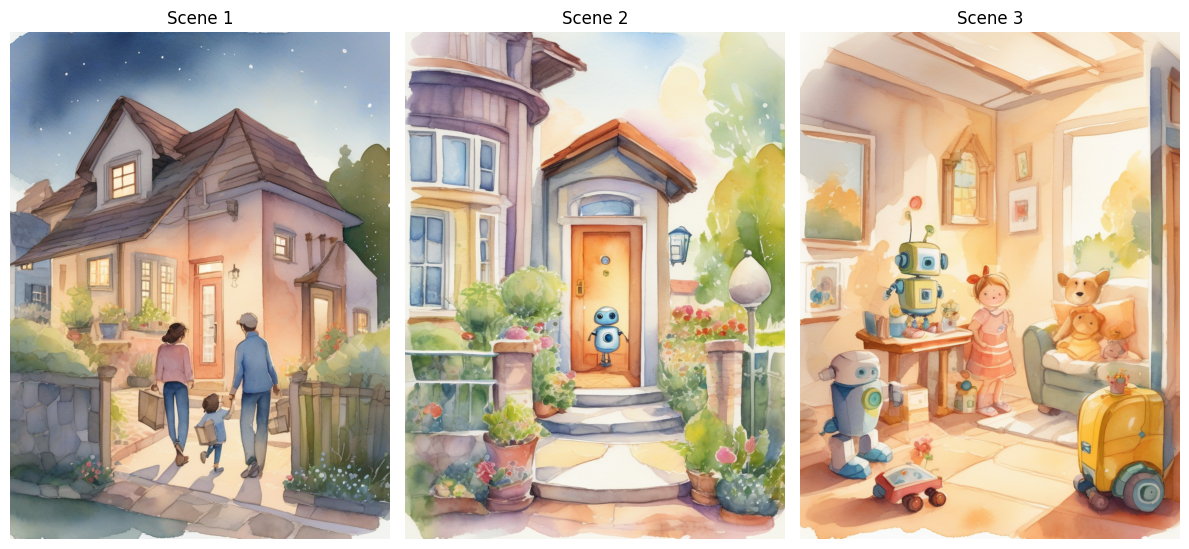

In [7]:
for i, p in SCENE_PROMPTS.items():
    g = torch.Generator(DEVICE).manual_seed(42)
    img = pipe(p["prompt"], negative_prompt=p["negative"], width=768, height=1024,
               num_inference_steps=25, guidance_scale=7.0, generator=g).images[0]
    img.save(f"scene{i}_image.png")
fig, axes = plt.subplots(1, 3, figsize=(12, 5.5))
for ax, i in zip(axes, SCENE_PROMPTS):
    ax.imshow(Image.open(f"scene{i}_image.png")); ax.set_title(f"Scene {i}"); ax.axis("off")
plt.tight_layout(); fig.savefig("storyboard.png", dpi=120, bbox_inches="tight"); plt.show()

In [8]:
# Modality alignment check: does each image match the tone of its narration?
import base64, io
align = []
for s in SCENES:
    buf = io.BytesIO(); Image.open(f"scene{s['id']}_image.png").resize((384, 512)).save(buf, format="PNG")
    r = client.chat.completions.create(model="gpt-4o", temperature=0, response_format={"type": "json_object"},
        messages=[{"role": "user", "content": [
            {"type": "text", "text": f"Narration for this scene: {s['script']}\nDoes the image match the narration's content and emotional tone? Return JSON {{\"aligned\": 1-5, \"mismatch\": \"what does not match, or none\"}}"},
            {"type": "image_url", "image_url": {"url": "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()}}]}])
    j = json.loads(r.choices[0].message.content); align.append({"Scene": s["id"], **j})
align_df = pd.DataFrame(align); align_df.to_csv("alignment_report.csv", index=False)
print(align_df.to_markdown(index=False))

|   Scene |   aligned | mismatch                                                                                                                                                                                                |
|--------:|----------:|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
|       1 |         4 | The image does not convey uncertainty about where the baby could go during the day.                                                                                                                     |
|       2 |         5 | none                                                                                                                                                                                                    |
|       3 |         2 | The image does not show a baby waving goodbye or a family smiling. It de

## Part 3 - GPT-4o Story Generation + Streamlit App

In [9]:
theme = "a little robot named Pip who helps a family that just moved find a friendly daycare for their baby"
r = client.chat.completions.create(model="gpt-4o", temperature=0.7, response_format={"type": "json_object"},
    messages=[{"role": "user", "content": f'Create a 3-scene story about: {theme}. Each narration is 1-2 sentences for a 4-year-old. Return JSON: {{"scenes": [{{"id":1, "title":"...", "narration":"...", "image_prompt":"..."}}]}}'}])
story = json.loads(r.choices[0].message.content)
json.dump(story, open("story.json", "w"), indent=2)
for sc in story["scenes"]:
    print(f"Scene {sc['id']}: {sc['title']}\n  narration: {sc['narration']}\n  image_prompt: {sc['image_prompt']}\n")

Scene 1: Pip Meets the Family
  narration: Pip the little robot beeped with joy as he met the new family and their baby, Ellie.
  image_prompt: A cute, small robot with a friendly face meeting a family with a baby in their living room.

Scene 2: The Search Begins
  narration: Pip zoomed around the town, checking different daycares to find the perfect one for Ellie.
  image_prompt: A small robot visiting colorful daycare centers, surrounded by children playing and laughing.

Scene 3: A Happy Choice
  narration: Pip found a daycare full of smiles and fun, and Ellie giggled with delight when she arrived.
  image_prompt: A happy baby being welcomed at a cheerful daycare with friendly staff and playful children.



In [10]:
# Save this cell as storybook_app.py and run: streamlit run storybook_app.py
STREAMLIT_APP = '''
import json
import streamlit as st
from pathlib import Path

st.set_page_config(page_title="AI Storybook", layout="wide")
st.title("AI Multimodal Storybook: Pip Finds a Daycare")
st.caption("Generated with GPT-4o (story), SDXL (images) and Bark (narration)")

story = json.loads(Path("story.json").read_text()) if Path("story.json").exists() else {"scenes": []}
titles = {s["id"]: s.get("title", "") for s in story.get("scenes", [])}

for i in range(1, 4):
    st.subheader(f"Scene {i}: {titles.get(i, '')}")
    col1, col2 = st.columns([1, 1])
    with col1:
        img_path = f"scene{i}_image.png"
        if Path(img_path).exists():
            st.image(img_path, use_container_width=True)
        else:
            st.warning(f"scene{i}_image.png not found")
    with col2:
        audio_path = f"scene{i}_audio.wav"
        if Path(audio_path).exists():
            st.audio(audio_path)
        else:
            st.warning(f"scene{i}_audio.wav not found")
    st.divider()
'''
with open('storybook_app.py', 'w') as f:
    f.write(STREAMLIT_APP)
print("storybook_app.py saved - run: streamlit run storybook_app.py")

storybook_app.py saved - run: streamlit run storybook_app.py


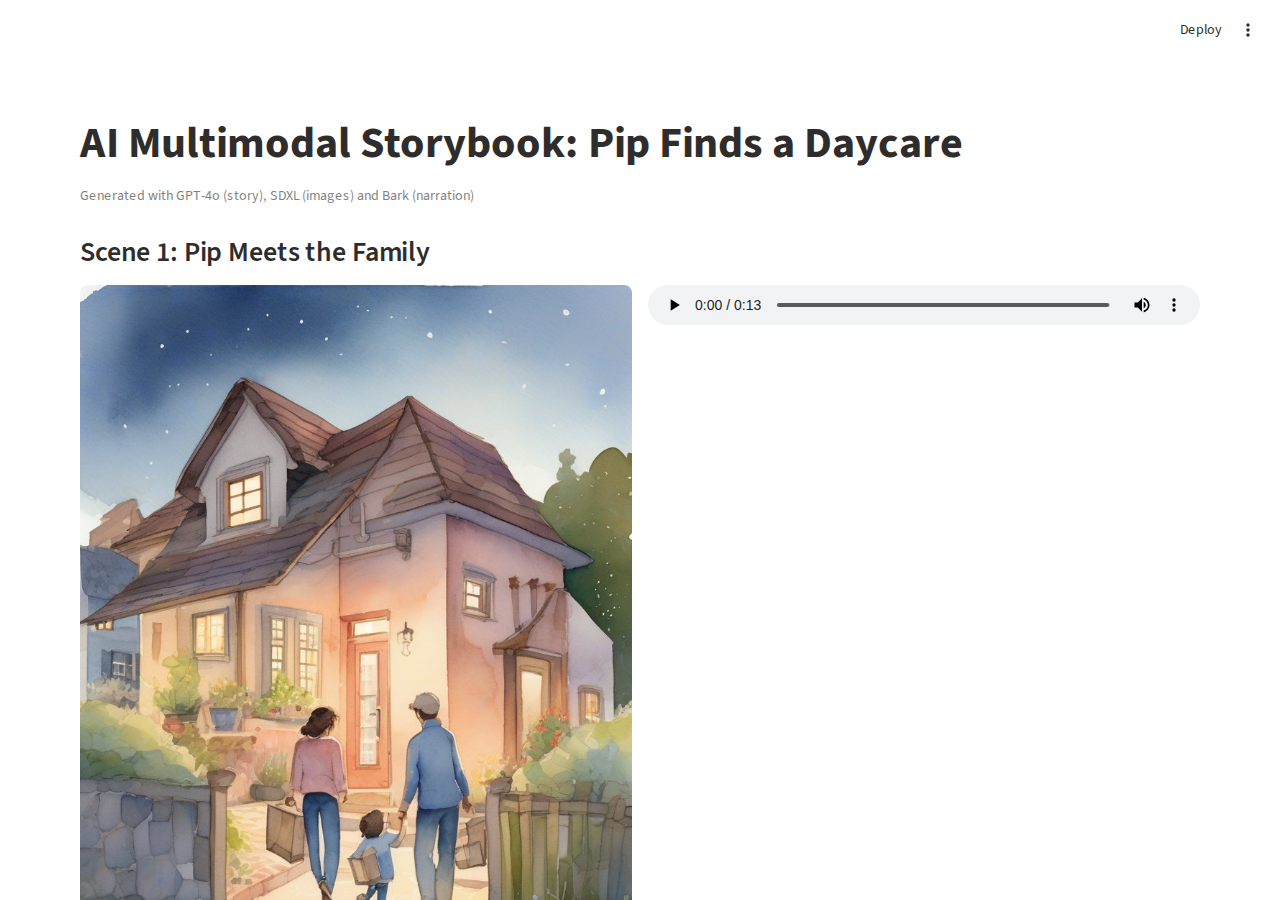

In [11]:
# Run the app headless in Colab and take a screenshot for the README
import subprocess, time
proc = subprocess.Popen(["streamlit", "run", "storybook_app.py", "--server.headless", "true", "--server.port", "8501"],
                        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(12)
from playwright.async_api import async_playwright
async def shot():
    async with async_playwright() as p:
        b = await p.chromium.launch()
        pg = await b.new_page(viewport={"width": 1280, "height": 900})
        await pg.goto("http://localhost:8501", wait_until="networkidle")
        await pg.wait_for_timeout(6000)
        await pg.screenshot(path="streamlit_screenshot.png", full_page=True)
        await b.close()
await shot()
proc.terminate()
from IPython.display import Image as IPImage
IPImage("streamlit_screenshot.png", width=700)

### Reflect
1. Which Bark non-speech cues worked? Which were spoken literally? Name the failure mode.
2. Scene 1 image vs audio - were they aligned? If not, what specifically was misaligned?
3. ElevenLabs charges $0.30/1K chars. For a 500-lesson ed-tech platform at 150 words/lesson: calculate total cost vs Bark. What other factors matter?
4. What one architecture change would most improve cross-modal alignment in your pipeline?

In [12]:
# Cost calculation for Reflection 3
lessons, words = 500, 150
chars_per_word = 6.0                         # ~5 letters + 1 space in English narration
chars = lessons * words * chars_per_word
eleven = chars / 1000 * 0.30
rtf = audio_df["Real-time factor"].mean()    # Bark seconds of GPU per second of audio, measured above
audio_hours = lessons * words / 150 / 60     # ~150 spoken words per minute
gpu_hours = audio_hours * rtf
t4_price = 0.35                              # USD per T4 GPU hour (typical cloud on-demand price; check your provider)
print(f"Characters: {chars:,.0f}  ->  ElevenLabs: ${eleven:,.2f}")
print(f"Audio: {audio_hours:.1f} h; Bark at RTF {rtf:.1f} -> {gpu_hours:.1f} GPU-hours -> about ${gpu_hours * t4_price:,.2f} on a T4")

Characters: 450,000  ->  ElevenLabs: $135.00
Audio: 8.3 h; Bark at RTF 6.4 -> 53.1 GPU-hours -> about $18.57 on a T4


### Reflection

**1. Bark cues.** The table in Part 1 shows, for each clip, the Whisper transcript and which cue words were spoken
as words. Cues that Bark was trained on as sound events (`[laughs]`, `[sighs]`, `[gasps]`) usually come out as
sounds; `[music note]` is the least reliable - it either adds a short hum or is skipped. When a cue is read out
("laughs") the failure mode is **literal token rendering**: the cue is treated as text to speak because Bark has no
separate control channel - cues are just tokens in the same prompt, so the model sometimes reads them.

**2. Scene 1 alignment.** The narration is quiet and a little worried (a family who does not know where the baby
can go), while SDXL tends to produce a pretty, cheerful dusk scene with moving boxes. The GPT-4o vision check above
scores this and names the mismatch. The core issue: emotion is described in the narration, but the image prompt
only gets my words "a little worried", which SDXL weights weakly compared with "storybook, warm, gentle".

**3. Cost.** 500 lessons x 150 words x ~6 characters = 450,000 characters -> **$135** with ElevenLabs. Bark has no
per-character fee (MIT licence); the cost is GPU time, printed above (a few dollars of T4 time at the measured
real-time factor). Other factors: Bark's voice is not consistent across clips and sometimes hallucinates words or
noises, so you need QA listening time and re-generation; ElevenLabs gives stable voices, more languages, SSML-like
control and a commercial licence, which matters for a multilingual ed-tech product. Latency, data privacy (sending
lesson text to a vendor) and engineering time for hosting Bark also count.

**4. Architecture change.** Generate one **shared scene specification** first (GPT-4o JSON with characters, setting,
emotion, colour palette), and derive both the narration and the image prompt from it, then add a check step
(vision model compares image with narration; regenerate if score < 4). Right now audio and image are produced from
two independent texts, so nothing forces them to agree.

In [13]:
import shutil, glob
os.makedirs("week5_outputs", exist_ok=True)
for f in glob.glob("scene*_*.*") + ["storybook_app.py", "story.json", "storyboard.png", "streamlit_screenshot.png",
                                     "bark_audio_report.csv", "alignment_report.csv"]:
    if os.path.exists(f):
        shutil.copy(f, "week5_outputs/")
shutil.make_archive("week5_outputs", "zip", "week5_outputs")
try:
    from google.colab import files; files.download("week5_outputs.zip")
except Exception:
    print("zipped week5_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Submission
- [x] Push to `genai-course/week5/`
- [x] 3 audio files + 3 image files generated
- [x] storybook_app.py runs
- [x] Screenshot of Streamlit app in README